# Breast Xenium input-ablation switches between cell-type families

Compare the 1- and 10-visible-neighbor-token models at 50% transcript removal. Cleaning and Leiden clustering retain the existing evaluation settings. Within each slice, clusters are first aligned one-to-one between models by maximizing cell overlap with the Hungarian algorithm. Each cluster then receives its **predominant annotated cell type**, then its Xenium UMAP color family: lymphoid, myeloid/innate, stromal/vascular, or malignant. A cell switches only when its cluster's family differs between models. Within-family type/cluster changes are not switches. Ties for predominant type and cells assigned to unmatched clusters are excluded from family-switch denominators and switched/stable comparisons.

This is a descriptive change in cluster association, not evidence that a cell's biological identity changed. Original maximum-overlap cluster switching remains available as `cluster_switched`. Family results use a separate output directory.


In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.insert(0, '/home/jwinchel/Syndri/context_analysis')
from input_ablation_cell_switch import DATA_ROOT, DEFAULT_OUTPUT, analyze_slice, recompute_family_switch_from_saved, CELL_TYPE_FAMILIES
SOURCE_OUTPUT = DEFAULT_OUTPUT.with_name(DEFAULT_OUTPUT.name + '_between_families')
OUTPUT = DEFAULT_OUTPUT.with_name(DEFAULT_OUTPUT.name + '_hungarian_between_families')
SAMPLES = sorted(p.stem for p in (DATA_ROOT / 'breast_xenium_k10_visible1').glob('GSM*rctd_annotated.h5ad'))
print(f'{len(SAMPLES)} slices found')

19 slices found


## Generate slice-level data

The analysis saves per-cell cluster assignments and removal counts, per-gene removals, Hungarian cluster matches, family transitions, and a summary for each slice. Set `RUN_MISSING = False` to inspect existing outputs without computing missing slices. Each slice may take several minutes.

In [2]:
# Reuse saved reproduced Leiden labels, recompute the Hungarian one-to-one mapping,
# and regenerate matched-cluster family transitions and per-cell switch labels.
for sample in SAMPLES:
    print('Updating:', sample)
    recompute_family_switch_from_saved(sample, SOURCE_OUTPUT, OUTPUT)
print(f'Recomputed Hungarian family transitions for {len(SAMPLES)} slices into {OUTPUT}')


Updating: GSM9509156_breast_breast_B17_B17_rctd_annotated
Updating: GSM9509157_breast_breast_B16_B16_rctd_annotated
Updating: GSM9509158_breast_breast_B15_B15_rctd_annotated
Updating: GSM9509159_breast_breast_B14_B14_rctd_annotated
Updating: GSM9509160_breast_breast_B2_B2_rctd_annotated
Updating: GSM9509161_breast_breast_B13_B13_rctd_annotated
Updating: GSM9509162_breast_breast_B12_B12_rctd_annotated
Updating: GSM9509163_breast_breast_B11_B11_rctd_annotated
Updating: GSM9509164_breast_breast_B10_B10_rctd_annotated
Updating: GSM9509165_breast_breast_B4_B4_rctd_annotated
Updating: GSM9509166_breast_breast_B9_B9_rctd_annotated
Updating: GSM9509167_breast_breast_B8_B8_rctd_annotated
Updating: GSM9509168_breast_breast_B7_B7_rctd_annotated
Updating: GSM9509169_breast_breast_B6_B6_rctd_annotated
Updating: GSM9509170_breast_breast_B3_B3_rctd_annotated
Updating: GSM9509171_breast_breast_B5_B5_rctd_annotated
Updating: GSM9509172_breast_breast_B1_B1_1_rctd_annotated
Updating: GSM9509173_breast_br

,slice,n_cells,n_switch_eligible,n_ambiguous,n_unmatched_cluster_cells,n_hungarian_cluster_matches,n_switched,switch_fraction,cluster_ari_1_vs_10,reproduced_scores_match_saved_1,reproduced_scores_match_saved_10
0,GSM9509156_breast_breast_B17_B17_rctd_annotated,68181,56874,0,11307,7,2808,0.049372,0.653775,False,False
1,GSM9509157_breast_breast_B16_B16_rctd_annotated,15990,15990,0,0,14,604,0.037774,0.881193,False,False
2,GSM9509158_breast_breast_B15_B15_rctd_annotated,33494,31262,0,2232,10,1518,0.048557,0.615793,False,False
3,GSM9509159_breast_breast_B14_B14_rctd_annotated,77383,77383,0,0,10,2797,0.036145,0.514451,False,False
4,GSM9509160_breast_breast_B2_B2_rctd_annotated,130957,126027,0,4930,11,18926,0.150174,0.640932,False,False
5,GSM9509161_breast_breast_B13_B13_rctd_annotated,37542,36139,0,1403,11,4411,0.122057,0.806555,False,False
6,GSM9509162_breast_breast_B12_B12_rctd_annotated,151364,141837,0,9527,10,4735,0.033383,0.517635,False,False
7,GSM9509163_breast_breast_B11_B11_rctd_annotated,79547,75429,0,4118,8,8154,0.108102,0.693779,False,False
8,GSM9509164_breast_breast_B10_B10_rctd_annotated,66079,66079,0,0,12,3628,0.054904,0.494896,False,False
9,GSM9509165_breast_breast_B4_B4_rctd_annotated,37902,37833,0,69,10,1429,0.037771,0.853120,False,False


Overall switch rate: 5.3%


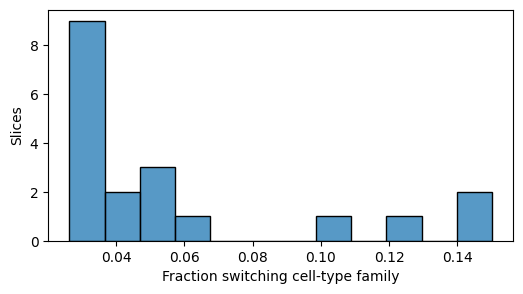

In [3]:
summaries = pd.DataFrame([json.loads(p.read_text()) for p in sorted(OUTPUT.glob('*/summary.json'))])
if summaries.empty: raise FileNotFoundError('No slice summaries yet; run the cell above')
display(summaries[['slice', 'n_cells', 'n_switch_eligible', 'n_ambiguous', 'n_unmatched_cluster_cells', 'n_hungarian_cluster_matches', 'n_switched', 'switch_fraction', 'cluster_ari_1_vs_10', 'reproduced_scores_match_saved_1', 'reproduced_scores_match_saved_10']])
print(f'Overall switch rate: {summaries.n_switched.sum() / summaries.n_switch_eligible.sum():.1%}')
fig, ax = plt.subplots(figsize=(6, 3))
sns.histplot(summaries.switch_fraction, bins=12, ax=ax)
ax.set(xlabel='Fraction switching cell-type family', ylabel='Slices')
plt.show()

## Cell-level gene-removal differences

switch_eligible
False      92801
True     1581125
Name: n_cells, dtype: int64

,modified_genes_1,modified_genes_10,zeroed_genes_1,zeroed_genes_10,removed_transcripts_1,removed_transcripts_10
switched,,,,,,
False,39.0,38.0,0.0,0.0,54.546074,54.989276
True,24.0,24.0,0.0,0.0,22.306739,22.758393


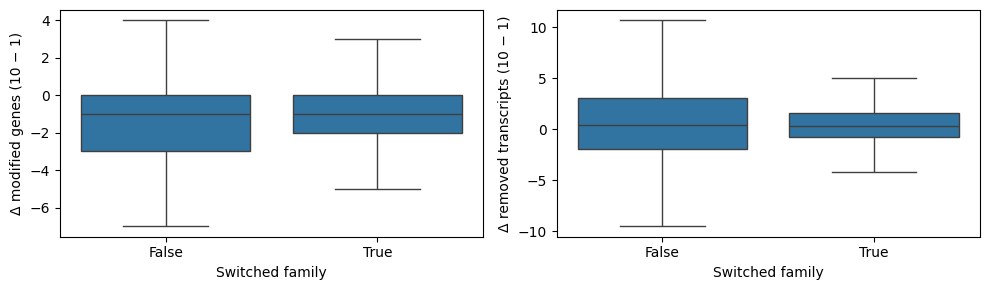

In [4]:
cells = pd.concat((pd.read_csv(p) for p in sorted(OUTPUT.glob('*/cells.csv.gz'))), ignore_index=True)
display(cells.groupby('switch_eligible').size().rename('n_cells'))
cells = cells.loc[cells['switch_eligible']].copy()
display(cells.groupby('switched')[['modified_genes_1', 'modified_genes_10', 'zeroed_genes_1', 'zeroed_genes_10', 'removed_transcripts_1', 'removed_transcripts_10']].median())
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.boxplot(data=cells, x='switched', y='delta_modified_genes_10_minus_1', showfliers=False, ax=axes[0])
sns.boxplot(data=cells, x='switched', y='delta_removed_transcripts_10_minus_1', showfliers=False, ax=axes[1])
axes[0].set(xlabel='Switched family', ylabel='Δ modified genes (10 − 1)')
axes[1].set(xlabel='Switched family', ylabel='Δ removed transcripts (10 − 1)')
plt.tight_layout()
plt.show()


## Between-family switching by original cell type

The pooled rate is weighted by the number of cells. The per-slice distribution shows heterogeneity without letting large slices dominate. Small cell-type/slice groups (fewer than 30 cells) are excluded from the per-slice plot.
The denominator includes only cells with unambiguous cluster-type assignments in both models.


,cell_type,n_cells,n_switched,n_slices,switch_fraction
8,mast cell,20021,4589,19,0.229209
4,fibroblast of breast,80350,9104,19,0.113304
13,plasmacytoid dendritic cell,22038,2338,19,0.106089
14,smooth muscle cell,121812,12490,19,0.102535
2,classical monocyte,105858,10775,19,0.101787
10,natural killer cell,11134,965,19,0.086671
12,plasma cell,60543,5217,19,0.086170
9,natural T-regulatory cell,26145,2170,19,0.082999
6,macrophage,57278,4016,19,0.070114
0,"CD4-positive, alpha-beta memory T cell",23323,1546,19,0.066286


,slice,cell_type,n_cells,n_switched,median_delta_genes,median_delta_transcripts,switch_fraction
0,GSM9509156_breast_breast_B17_B17_rctd_annotated,"CD4-positive, alpha-beta memory T cell",493,57,-1.0,-0.086789,0.115619
15,GSM9509157_breast_breast_B16_B16_rctd_annotated,"CD4-positive, alpha-beta memory T cell",1075,48,0.0,-0.193431,0.044651
30,GSM9509158_breast_breast_B15_B15_rctd_annotated,"CD4-positive, alpha-beta memory T cell",204,20,-1.0,-0.116102,0.098039
45,GSM9509159_breast_breast_B14_B14_rctd_annotated,"CD4-positive, alpha-beta memory T cell",692,32,-1.0,-0.085116,0.046243
60,GSM9509160_breast_breast_B2_B2_rctd_annotated,"CD4-positive, alpha-beta memory T cell",629,192,-1.0,-0.068153,0.305246
...,...,...,...,...,...,...,...
224,GSM9509170_breast_breast_B3_B3_rctd_annotated,smooth muscle cell,7356,362,1.0,0.140469,0.049212
239,GSM9509171_breast_breast_B5_B5_rctd_annotated,smooth muscle cell,12061,309,0.0,0.451156,0.025620
254,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,smooth muscle cell,9956,494,0.0,0.568024,0.049618
269,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,smooth muscle cell,12060,279,0.0,0.492296,0.023134


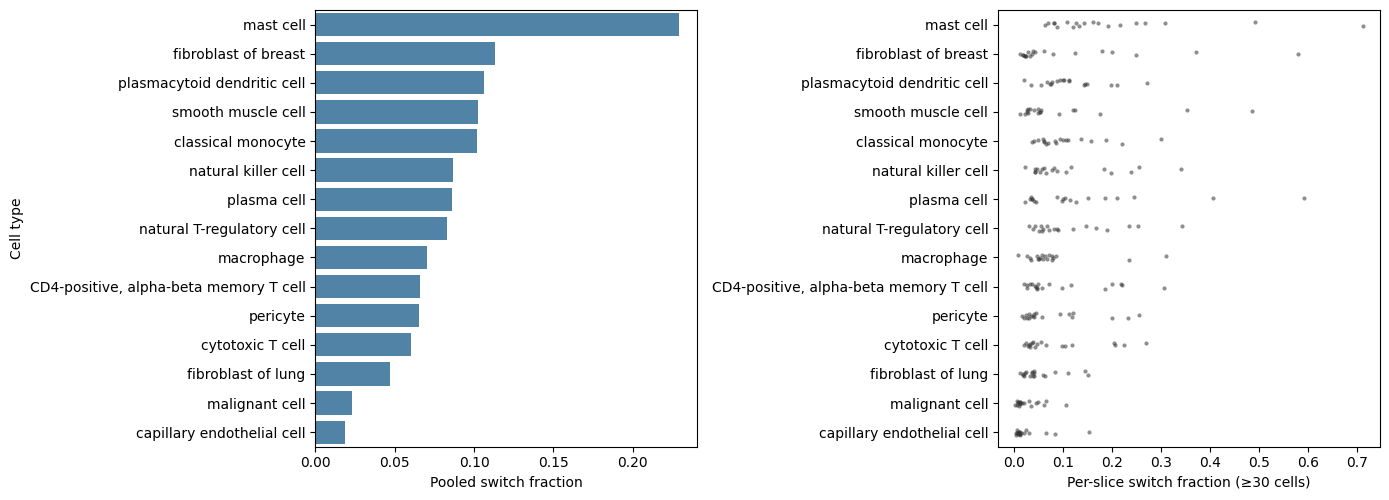

In [5]:
by_type_slice = cells.groupby(['slice', 'cell_type'], as_index=False).agg(n_cells=('switched', 'size'), n_switched=('switched', 'sum'), median_delta_genes=('delta_modified_genes_10_minus_1', 'median'), median_delta_transcripts=('delta_removed_transcripts_10_minus_1', 'median'))
by_type_slice['switch_fraction'] = by_type_slice.n_switched / by_type_slice.n_cells
by_type = by_type_slice.groupby('cell_type', as_index=False).agg(n_cells=('n_cells', 'sum'), n_switched=('n_switched', 'sum'), n_slices=('slice', 'nunique'))
by_type['switch_fraction'] = by_type.n_switched / by_type.n_cells
by_type = by_type.sort_values('switch_fraction', ascending=False)
display(by_type)
display(by_type_slice.sort_values(['cell_type', 'slice']))
by_type.to_csv(OUTPUT / 'switch_by_cell_type.csv', index=False)
by_type_slice.to_csv(OUTPUT / 'switch_by_cell_type_and_slice.csv', index=False)
plot_types = by_type.loc[by_type.n_cells >= 100, 'cell_type']
fig, axes = plt.subplots(1, 2, figsize=(14, max(4, 0.34 * len(plot_types))))
sns.barplot(data=by_type[by_type.cell_type.isin(plot_types)], x='switch_fraction', y='cell_type', order=list(plot_types), color='#4385b5', ax=axes[0])
sns.stripplot(data=by_type_slice[(by_type_slice.n_cells >= 30) & by_type_slice.cell_type.isin(plot_types)], x='switch_fraction', y='cell_type', order=list(plot_types), color='#333333', alpha=.55, size=3, ax=axes[1])
axes[0].set(xlabel='Pooled switch fraction', ylabel='Cell type')
axes[1].set(xlabel='Per-slice switch fraction (≥30 cells)', ylabel='')
plt.tight_layout()
plt.show()


In [6]:
removal_by_type = cells.groupby(['cell_type', 'switched'], as_index=False).agg(n_cells=('cell_id', 'size'), median_delta_modified_genes=('delta_modified_genes_10_minus_1', 'median'), median_delta_removed_transcripts=('delta_removed_transcripts_10_minus_1', 'median'))
display(removal_by_type.sort_values(['cell_type', 'switched']))
removal_by_type.to_csv(OUTPUT / 'removal_by_cell_type_and_switch_status.csv', index=False)

,cell_type,switched,n_cells,median_delta_modified_genes,median_delta_removed_transcripts
0,"CD4-positive, alpha-beta memory T cell",False,21777,-1.0,-0.156756
1,"CD4-positive, alpha-beta memory T cell",True,1546,-1.0,-0.177703
2,capillary endothelial cell,False,90808,0.0,-0.641600
3,capillary endothelial cell,True,1737,0.0,-0.571771
4,classical monocyte,False,95083,-1.0,-0.117961
5,classical monocyte,True,10775,-1.0,0.022519
6,cytotoxic T cell,False,52493,-1.0,0.045385
7,cytotoxic T cell,True,3366,-1.0,0.029865
8,fibroblast of breast,False,71246,-1.0,0.130607
9,fibroblast of breast,True,9104,-1.0,0.130711


## Genes with the largest removal differences

Normalize each slice by its cell count before averaging so large slices do not dominate.

The saved per-gene files contain totals by gene, not per-cell gene-removal matrices, so this panel reports overall removal differences only; it does not stratify genes by the updated switched/stable cell groups.


,gene,delta_per_cell
196,ENSG00000170421,-0.266169
31,ENSG00000091831,-0.263368
209,ENSG00000173467,-0.215730
61,ENSG00000110092,-0.197360
234,ENSG00000184292,-0.190731
52,ENSG00000107485,-0.163372
116,ENSG00000135480,-0.083593
54,ENSG00000107796,-0.063045
164,ENSG00000159216,-0.058206
210,ENSG00000173801,-0.057189


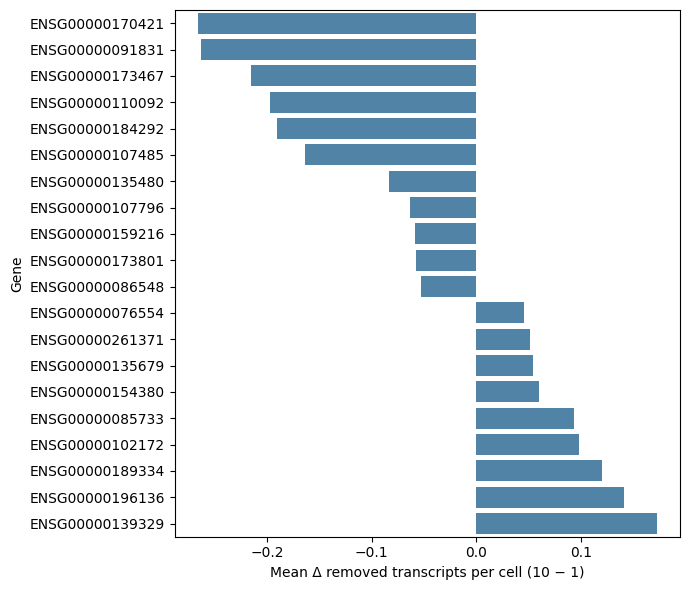

In [7]:
genes = pd.concat((pd.read_csv(p) for p in sorted(OUTPUT.glob('*/genes.csv'))), ignore_index=True)
genes = genes.merge(summaries[['slice', 'n_cells']], on='slice', validate='many_to_one')
genes['delta_per_cell'] = genes.delta_removed_transcripts_10_minus_1 / genes.n_cells
gene_summary = genes.groupby('gene', as_index=False).agg(delta_per_cell=('delta_per_cell', 'mean'))
top = gene_summary.loc[gene_summary.delta_per_cell.abs().nlargest(20).index].sort_values('delta_per_cell')
display(top)
fig, ax = plt.subplots(figsize=(7, 6))
sns.barplot(data=top, x='delta_per_cell', y='gene', color='#4385b5', ax=ax)
ax.set(xlabel='Mean Δ removed transcripts per cell (10 − 1)', ylabel='Gene')
plt.tight_layout()
plt.show()


## Leiden cluster composition by cell type

Each row in the exported long table is one slice, model, cluster, and cell type. `fraction_of_cluster` sums to 1 within each cluster; `fraction_of_cell_type` shows where a cell type falls across clusters. The predominant type is a descriptive label only, not a ground-truth annotation. Cluster IDs are local to each slice and model; `hungarian_cluster_matches.csv` records the one-to-one alignment and family of each matched cluster pair.

In [8]:
composition_parts = []
for model, cluster_col in [(1, 'cluster_1'), (10, 'cluster_10')]:
    part = cells.groupby(['slice', cluster_col, 'cell_type'], observed=True).size().rename('n_cells').reset_index().rename(columns={cluster_col: 'cluster'})
    part['model_visible_tokens'] = model
    part['cluster_size'] = part.groupby(['slice', 'cluster'])['n_cells'].transform('sum')
    part['cell_type_size'] = part.groupby(['slice', 'cell_type'])['n_cells'].transform('sum')
    part['fraction_of_cluster'] = part.n_cells / part.cluster_size
    part['fraction_of_cell_type'] = part.n_cells / part.cell_type_size
    composition_parts.append(part)
cluster_composition = pd.concat(composition_parts, ignore_index=True)
cluster_composition = cluster_composition[['slice', 'model_visible_tokens', 'cluster', 'cell_type', 'n_cells', 'cluster_size', 'fraction_of_cluster', 'cell_type_size', 'fraction_of_cell_type']]
cluster_composition.to_csv(OUTPUT / 'cluster_cell_type_composition.csv', index=False)
predominant = cluster_composition.sort_values(['slice', 'model_visible_tokens', 'cluster', 'n_cells', 'cell_type'], ascending=[True, True, True, False, True]).drop_duplicates(['slice', 'model_visible_tokens', 'cluster'])
predominant = predominant[['slice', 'model_visible_tokens', 'cluster', 'cell_type', 'n_cells', 'cluster_size', 'fraction_of_cluster']].rename(columns={'cell_type': 'predominant_cell_type', 'n_cells': 'predominant_type_cells', 'fraction_of_cluster': 'predominant_type_fraction'})
predominant.to_csv(OUTPUT / 'cluster_predominant_cell_type.csv', index=False)
display(predominant.head(30))

,slice,model_visible_tokens,cluster,predominant_cell_type,predominant_type_cells,cluster_size,predominant_type_fraction
1,GSM9509156_breast_breast_B17_B17_rctd_annotated,1,0,capillary endothelial cell,2103,3048,0.689961
19,GSM9509156_breast_breast_B17_B17_rctd_annotated,1,1,fibroblast of lung,4042,8806,0.459005
36,GSM9509156_breast_breast_B17_B17_rctd_annotated,1,2,malignant cell,9496,10208,0.930251
58,GSM9509156_breast_breast_B17_B17_rctd_annotated,1,3,smooth muscle cell,1830,7104,0.257601
61,GSM9509156_breast_breast_B17_B17_rctd_annotated,1,4,classical monocyte,5006,10930,0.458005
77,GSM9509156_breast_breast_B17_B17_rctd_annotated,1,5,cytotoxic T cell,937,1836,0.510349
93,GSM9509156_breast_breast_B17_B17_rctd_annotated,1,6,malignant cell,14753,14942,0.987351
2602,GSM9509156_breast_breast_B17_B17_rctd_annotated,10,0,capillary endothelial cell,2069,3069,0.674161
2621,GSM9509156_breast_breast_B17_B17_rctd_annotated,10,2,fibroblast of lung,4155,9039,0.459675
2645,GSM9509156_breast_breast_B17_B17_rctd_annotated,10,3,smooth muscle cell,1862,8974,0.207488


In [9]:
cell_type_order = [
    # Lymphoid
    "CD4-positive, alpha-beta memory T cell",
    "cytotoxic T cell",
    "natural T-regulatory cell",
    "natural killer cell",
    "plasma cell",

    # Myeloid / innate
    "classical monocyte",
    "macrophage",
    "mast cell",
    "plasmacytoid dendritic cell",

    # Stromal / vascular
    "capillary endothelial cell",
    "fibroblast of breast",
    "fibroblast of lung",
    "pericyte",
    "smooth muscle cell",

    # Malignant
    "malignant cell",
]

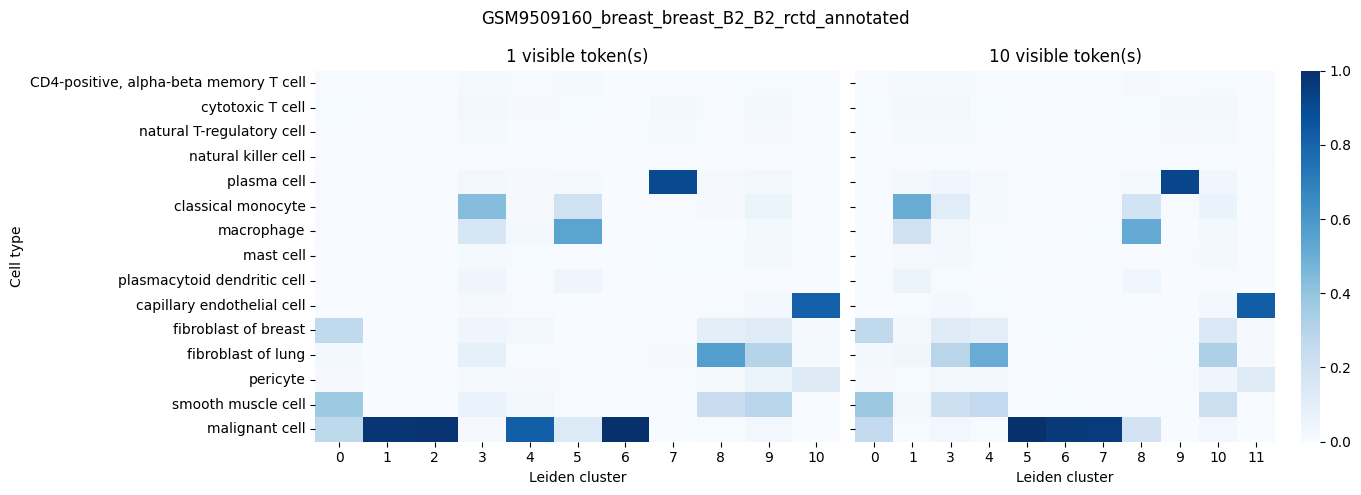

In [10]:
COMPOSITION_SLICE = summaries.sort_values('switch_fraction', ascending=False).iloc[0]['slice']
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, model in zip(axes, [1, 10]):
    subset = cluster_composition[(cluster_composition['slice'] == COMPOSITION_SLICE) & (cluster_composition.model_visible_tokens == model)]
    heatmap = subset.pivot(index='cell_type', columns='cluster', values='fraction_of_cluster').fillna(0)
    heatmap = heatmap.reindex(cell_type_order, fill_value=0)
    sns.heatmap(heatmap, cmap='Blues', vmin=0, vmax=1, ax=ax, cbar=(model == 10))
    ax.set(title=f'{model} visible token(s)', xlabel='Leiden cluster', ylabel='Cell type' if model == 1 else '')
fig.suptitle(COMPOSITION_SLICE)
plt.tight_layout()
plt.show()


## Inspect family transitions and switched cells

Counts below compare cluster-associated families after Hungarian alignment. Cells whose clusters are unmatched or have ambiguous predominant types are excluded. Numeric and aligned Leiden cluster IDs remain in the per-cell exports.


,cluster_1,cluster_10,cluster_10_aligned,n_overlap_cells,predominant_type_1,family_1,predominant_type_10,family_10,family_switched
0,0,0,0,12337,malignant cell,Malignant,smooth muscle cell,Stromal / vascular,True
1,1,7,1,17288,malignant cell,Malignant,malignant cell,Malignant,False
2,2,6,2,10366,malignant cell,Malignant,malignant cell,Malignant,False
3,3,1,3,13561,classical monocyte,Myeloid / innate,classical monocyte,Myeloid / innate,False
4,4,3,4,62,malignant cell,Malignant,fibroblast of lung,Stromal / vascular,True
5,5,8,5,2928,macrophage,Myeloid / innate,macrophage,Myeloid / innate,False
6,6,5,6,21894,malignant cell,Malignant,malignant cell,Malignant,False
7,7,9,7,2696,plasma cell,Lymphoid,plasma cell,Lymphoid,False
8,8,4,8,11509,fibroblast of lung,Stromal / vascular,fibroblast of lung,Stromal / vascular,False
9,9,10,9,2939,fibroblast of lung,Stromal / vascular,fibroblast of lung,Stromal / vascular,False


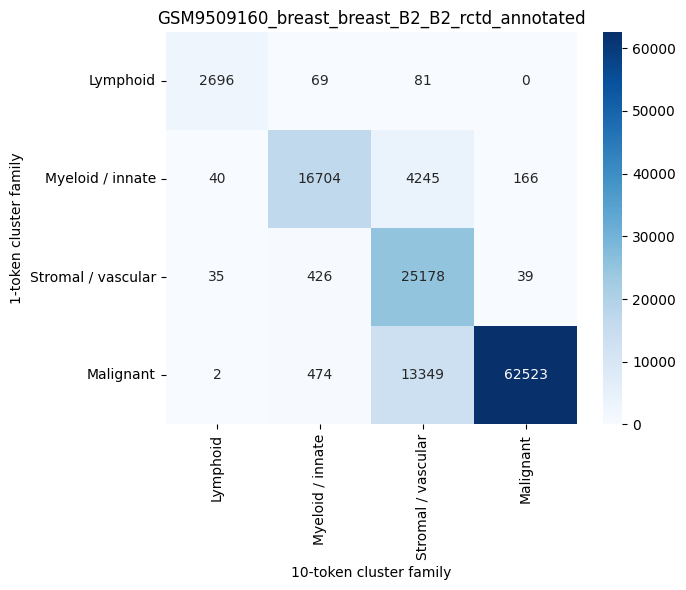

,slice,cell_id,cell_type,x_centroid,y_centroid,cluster_1,cluster_10,cluster_10_aligned,switched,raw_transcripts,...,cluster_switched,annotated_family,predominant_type_1,family_1,predominant_type_10,family_10,switch_eligible,delta_modified_genes_10_minus_1,delta_removed_transcripts_10_minus_1,cluster_match_eligible
195048,GSM9509160_breast_breast_B2_B2_rctd_annotated,GSM9509160_breast_breast_B2_B2:aaaaagko-1,smooth muscle cell,1066.843506,1703.959595,0,0,0,True,112,...,False,Stromal / vascular,malignant cell,Malignant,smooth muscle cell,Stromal / vascular,True,1,-1.394023,True
195049,GSM9509160_breast_breast_B2_B2_rctd_annotated,GSM9509160_breast_breast_B2_B2:aaaafimp-1,fibroblast of breast,1065.842773,1714.901245,0,0,0,True,141,...,False,Stromal / vascular,malignant cell,Malignant,smooth muscle cell,Stromal / vascular,True,0,1.318948,True
195098,GSM9509160_breast_breast_B2_B2_rctd_annotated,GSM9509160_breast_breast_B2_B2:aabcbmal-1,malignant cell,1194.428345,1690.316406,6,8,5,True,390,...,True,Malignant,malignant cell,Malignant,macrophage,Myeloid / innate,True,-9,-32.369912,True
195117,GSM9509160_breast_breast_B2_B2_rctd_annotated,GSM9509160_breast_breast_B2_B2:aabkkgng-1,smooth muscle cell,857.411682,2179.541504,3,3,4,True,36,...,True,Stromal / vascular,classical monocyte,Myeloid / innate,fibroblast of lung,Stromal / vascular,True,-2,-2.091683,True
195119,GSM9509160_breast_breast_B2_B2_rctd_annotated,GSM9509160_breast_breast_B2_B2:aabkmmnk-1,plasma cell,843.840454,2174.739258,7,3,4,True,22,...,True,Lymphoid,plasma cell,Lymphoid,fibroblast of lung,Stromal / vascular,True,-2,-1.088042,True
195134,GSM9509160_breast_breast_B2_B2_rctd_annotated,GSM9509160_breast_breast_B2_B2:aacfcnhd-1,fibroblast of lung,818.173584,2244.139404,3,3,4,True,10,...,True,Stromal / vascular,classical monocyte,Myeloid / innate,fibroblast of lung,Stromal / vascular,True,0,-1.318805,True
195136,GSM9509160_breast_breast_B2_B2_rctd_annotated,GSM9509160_breast_breast_B2_B2:aacfiodb-1,plasma cell,832.637817,2248.530762,7,10,9,True,18,...,True,Lymphoid,plasma cell,Lymphoid,fibroblast of lung,Stromal / vascular,True,-3,-1.800652,True
195144,GSM9509160_breast_breast_B2_B2_rctd_annotated,GSM9509160_breast_breast_B2_B2:aacigljj-1,plasma cell,840.397644,2271.794678,3,3,4,True,15,...,True,Lymphoid,classical monocyte,Myeloid / innate,fibroblast of lung,Stromal / vascular,True,-1,-0.154454,True
195148,GSM9509160_breast_breast_B2_B2_rctd_annotated,GSM9509160_breast_breast_B2_B2:aacjjgpe-1,fibroblast of lung,844.284546,2300.432373,8,9,7,True,64,...,True,Stromal / vascular,fibroblast of lung,Stromal / vascular,plasma cell,Lymphoid,True,1,-0.157481,True
195218,GSM9509160_breast_breast_B2_B2_rctd_annotated,GSM9509160_breast_breast_B2_B2:aaechafh-1,classical monocyte,1402.182251,2529.843750,10,1,3,True,12,...,True,Myeloid / innate,capillary endothelial cell,Stromal / vascular,classical monocyte,Myeloid / innate,True,1,0.560588,True


In [11]:
SLICE = summaries.sort_values('switch_fraction', ascending=False).iloc[0]['slice']
transitions = pd.read_csv(OUTPUT / SLICE / 'family_transitions.csv')
cluster_matches = pd.read_csv(OUTPUT / SLICE / 'hungarian_cluster_matches.csv')
display(cluster_matches.sort_values('cluster_1'))
family_order = list(dict.fromkeys(CELL_TYPE_FAMILIES.values()))
matrix = transitions.pivot(index='family_1', columns='family_10', values='n_cells').fillna(0)
matrix = matrix.reindex(index=family_order, columns=family_order, fill_value=0)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(matrix, cmap='Blues', annot=True, fmt='.0f', ax=ax)
ax.set(title=SLICE, xlabel='10-token cluster family', ylabel='1-token cluster family')
plt.tight_layout()
plt.show()
display(cells.loc[cells['slice'].eq(SLICE) & cells.switched].head(20))


In [16]:
cells[cells['switched']&cells['cluster_match_eligible']]

,slice,cell_id,cell_type,x_centroid,y_centroid,cluster_1,cluster_10,cluster_10_aligned,switched,raw_transcripts,...,cluster_switched,annotated_family,predominant_type_1,family_1,predominant_type_10,family_10,switch_eligible,delta_modified_genes_10_minus_1,delta_removed_transcripts_10_minus_1,cluster_match_eligible
11,GSM9509156_breast_breast_B17_B17_rctd_annotated,GSM9509156_breast_breast_B17_B17:aaancklp-1,classical monocyte,1145.924805,2542.637939,4,3,3,True,12,...,True,Myeloid / innate,classical monocyte,Myeloid / innate,smooth muscle cell,Stromal / vascular,True,-3,-2.214447,True
30,GSM9509156_breast_breast_B17_B17_rctd_annotated,GSM9509156_breast_breast_B17_B17:aabkhlaf-1,classical monocyte,1286.528931,2532.277344,4,2,1,True,104,...,True,Myeloid / innate,classical monocyte,Myeloid / innate,fibroblast of lung,Stromal / vascular,True,-1,-0.020152,True
76,GSM9509156_breast_breast_B17_B17_rctd_annotated,GSM9509156_breast_breast_B17_B17:aadlkiaj-1,classical monocyte,1666.659790,2716.514893,4,3,3,True,25,...,True,Myeloid / innate,classical monocyte,Myeloid / innate,smooth muscle cell,Stromal / vascular,True,-1,-0.915390,True
202,GSM9509156_breast_breast_B17_B17_rctd_annotated,GSM9509156_breast_breast_B17_B17:aakdcmee-1,cytotoxic T cell,991.610535,2540.846680,4,5,5,True,95,...,True,Lymphoid,classical monocyte,Myeloid / innate,cytotoxic T cell,Lymphoid,True,-1,0.051333,True
260,GSM9509156_breast_breast_B17_B17_rctd_annotated,GSM9509156_breast_breast_B17_B17:aanhkben-1,fibroblast of lung,3309.016113,768.933716,3,6,2,True,38,...,True,Stromal / vascular,smooth muscle cell,Stromal / vascular,malignant cell,Malignant,True,2,0.583143,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1673826,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,GSM9509174_breast_breast_B1_B1_3:oifmnmig-1,cytotoxic T cell,4971.102539,1316.869873,3,8,2,True,41,...,True,Lymphoid,cytotoxic T cell,Lymphoid,fibroblast of lung,Stromal / vascular,True,0,1.385690,True
1673831,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,GSM9509174_breast_breast_B1_B1_3:oifobmgm-1,malignant cell,4989.272461,1204.046997,2,4,8,True,17,...,True,Malignant,fibroblast of lung,Stromal / vascular,malignant cell,Malignant,True,4,2.805185,True
1673842,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,GSM9509174_breast_breast_B1_B1_3:oigckohc-1,natural T-regulatory cell,5030.094727,1326.982300,2,7,3,True,19,...,True,Lymphoid,fibroblast of lung,Stromal / vascular,cytotoxic T cell,Lymphoid,True,-3,-0.634539,True
1673914,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,GSM9509174_breast_breast_B1_B1_3:oiihfkoi-1,fibroblast of breast,5149.600098,1599.303833,0,8,2,True,46,...,True,Stromal / vascular,classical monocyte,Myeloid / innate,fibroblast of lung,Stromal / vascular,True,0,1.048134,True
